<a href="https://colab.research.google.com/github/yordy2069/PrimerCicloU/blob/main/Proyectoalgebra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aplicaciones de Álgebra Lineal en Procesamiento y Compresión de Imágenes

Este cuaderno de Google Colab presenta la implementación práctica de conceptos de **Álgebra Lineal** aplicados al procesamiento digital de imágenes. Una imagen digital en escala de grises no es más que una **matriz bidimensional** $A \in \mathbb{R}^{m \times n}$, donde cada elemento $a_{i,j}$ (píxel) representa la intensidad luminosa en una coordenada espacial.

---

## Configuración Inicial y Descarga de Imagen de Prueba

En esta sección importamos las librerías necesarias (`numpy`, `matplotlib`, `cv2` y `urllib`) y descargamos una imagen de internet de forma automática para asegurar que el cuaderno sea reproducible de inmediato sin intervención manual.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# ==========================================
# CONTROL CENTRALIZADO DE LA IMAGEN A PROCESAR
# Cambia esta ruta para procesar tu propia imagen en todo el cuaderno
# ==========================================
IMAGE_PATH = '/content/imagen2.jpg'
print(f"Ruta activa para el procesamiento de imágenes: '{IMAGE_PATH}'")

Ruta activa para el procesamiento de imágenes: '/content/imagen2.jpg'


## Proceso 1: Carga y Representación Matricial

### Concepto de Álgebra Lineal:
Una imagen a color se representa como un tensor de orden 3 ($m \times n \times 3$), donde los canales corresponden a los componentes Rojo, Verde y Azul (RGB). Al convertirla a escala de grises, realizamos una **proyección ortogonal** o una combinación lineal de los canales de color para obtener un espacio unidimensional por píxel:

$$Y = 0.299 \cdot R + 0.587 \cdot G + 0.114 \cdot B$$

Esto nos da como resultado una única matriz real $A \in \mathbb{R}^{m \times n}$.

--- Propiedades de la Matriz de la Imagen Activa ---
Dimensiones de la imagen a color (Tensor): (529, 378, 3)
Dimensiones de la imagen en grises (Matriz): (529, 378) (529x378)


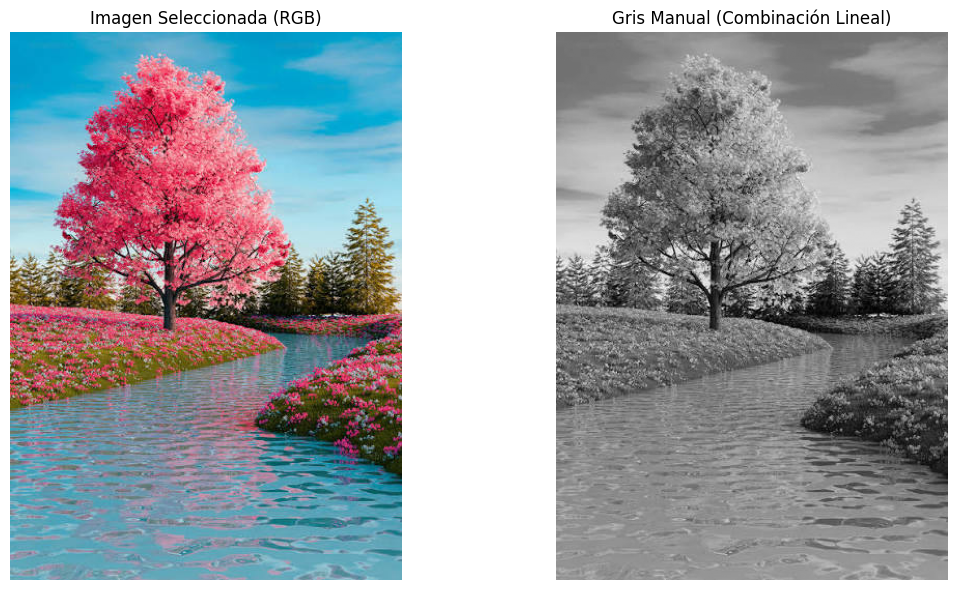

In [7]:
# 1. Cargar la imagen utilizando la variable centralizada IMAGE_PATH
img_bgr = cv2.imread(IMAGE_PATH)

if img_bgr is None: # verificar si la imagen cargó correctamente
    raise FileNotFoundError(f"No se pudo cargar la imagen en la ruta: '{IMAGE_PATH}'. Verifica que el archivo exista.")

# 2. Convertir la imagen a escala de grises (Automático usando OpenCV)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# ==========================================================
# CONVERSIÓN MANUAL A ESCALA DE GRISES (Combinación Lineal)
# ==========================================================
blue_channel = img_bgr[:, :, 0]
green_channel = img_bgr[:, :, 1]
red_channel = img_bgr[:, :, 2]

# Aplicamos la combinación lineal manual de forma matricial
img_gray_manual = (0.299 * red_channel + 0.587 * green_channel + 0.114 * blue_channel).astype(np.uint8)

# 3. Analizar propiedades dimensionales
filas, columnas = img_gray.shape
print("--- Propiedades de la Matriz de la Imagen Activa ---")
print(f"Dimensiones de la imagen a color (Tensor): {img_bgr.shape}")
print(f"Dimensiones de la imagen en grises (Matriz): {img_gray.shape} ({filas}x{columnas})")

# 4. Mostrar únicamente la imagen seleccionada y la conversión manual
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title("Imagen Seleccionada (RGB)")
axes[0].axis('off')

axes[1].imshow(img_gray_manual, cmap='gray')
axes[1].set_title("Gris Manual (Combinación Lineal)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

## Proceso 2: Filtro de Suavizado (Convolución 2D)

### Concepto de Álgebra Lineal:
La convolución digital 2D es un operador lineal. Consiste en desplazar una submatriz llamada **Kernel** o máscara $K \in \mathbb{R}^{k \times k}$ sobre la matriz de la imagen $A$. Cada píxel de salida se calcula mediante el producto interno (de Frobenius) de la vecindad de la imagen con el kernel, que actúa como un **promedio ponderado local**:

$$B(i,j) = \sum_{s=-a}^{a} \sum_{t=-b}^{b} K(s,t) \cdot A(i-s, j-t)$$

Un kernel de promediado homogéneo de tamaño $5 \times 5$ se define como la matriz constante ponderada:

$$K = \frac{1}{25} \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

Esto atenúa las altas frecuencias (el ruido) actuando como un filtro paso bajo.

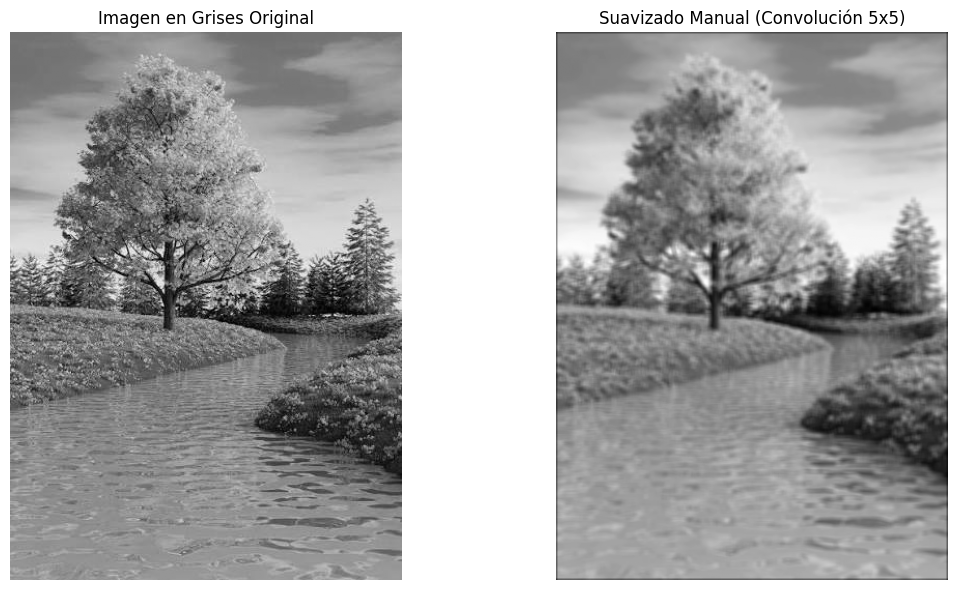

In [8]:
# 1. Definir un Kernel de suavizado 5x5 de promediado homogéneo
kernel_suavizado = np.ones((5, 5), dtype=np.float32) / 25.0

# Convolución Automática
img_suavizada = cv2.filter2D(img_gray, -1, kernel_suavizado)

# ==========================================================
# CONVOLUCIÓN MANUAL (Filtro de Suavizado)
# ==========================================================
def convolucion_manual(imagen, kernel):
    m, n = imagen.shape
    k_h, k_w = kernel.shape
    pad_h = k_h // 2
    pad_w = k_w // 2

    imagen_padded = np.pad(imagen, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    salida = np.zeros_like(imagen, dtype=np.float32)

    for i in range(m):
        for j in range(n):
            region = imagen_padded[i:i+k_h, j:j+k_w]
            salida[i, j] = np.sum(region * kernel)
    return salida

img_suavizada_manual = convolucion_manual(img_gray, kernel_suavizado)
img_suavizada_manual = np.clip(img_suavizada_manual, 0, 255).astype(np.uint8)

# 3. Visualizar únicamente los resultados comparativos esenciales
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title("Imagen en Grises Original")
axes[0].axis('off')

axes[1].imshow(img_suavizada_manual, cmap='gray')
axes[1].set_title("Suavizado Manual (Convolución 5x5)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

## Proceso 4: Transformación de Contraste y Brillo

### Concepto de Álgebra Lineal:
Ajustar el brillo y contraste es una **transformación afín** sobre la matriz de la imagen. Involucra dos operaciones algebraicas básicas:
1. **Multiplicación por un escalar (Contraste $\alpha$):** Escala el rango dinámico de las intensidades.
2. **Adición de matrices (Brillo $\beta$):** Suma un valor constante ponderado mediante una matriz identidad modificada o matriz de unos $I$ escalada.

Fórmula matemática aplicada a cada píxel (elemento matricial):

$$A'_{i,j} = \alpha \cdot A_{i,j} + \beta$$

Donde:
* Si $\alpha > 1$, aumenta el contraste; si $\alpha < 1$, disminuye.
* Si $\beta > 0$, aumenta el brillo global; si $\beta < 0$, disminuye.

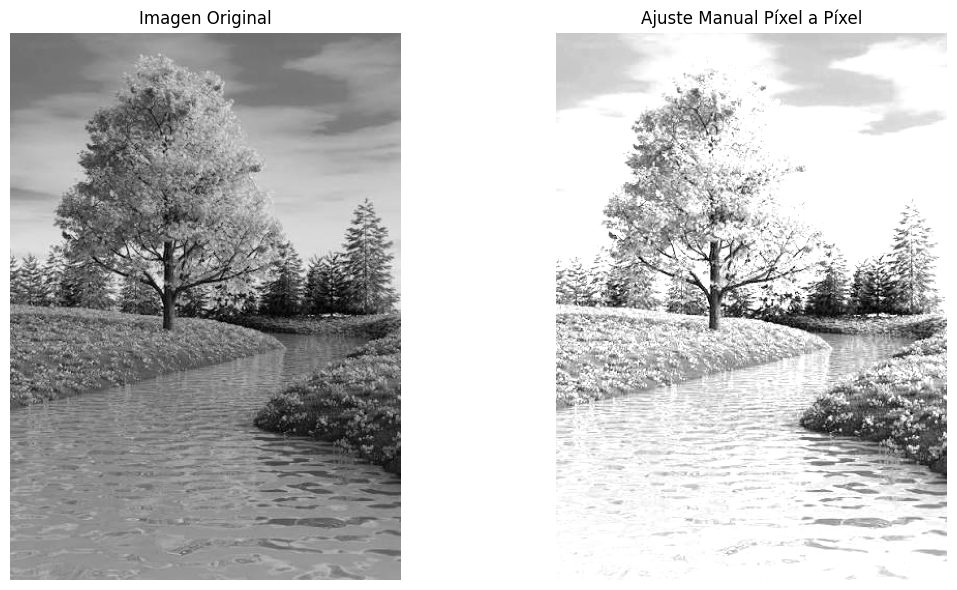

In [10]:
# Parámetros de la transformación lineal
alpha = 1.5  # Escalar de contraste
beta = 40.0  # Escalar de brillo

# Transformación Automática usando operaciones vectorizadas
img_transformada = alpha * img_gray.astype(np.float32) + beta
img_transformada = np.clip(img_transformada, 0, 255).astype(np.uint8)

# ==========================================================
# TRANSFORMACIÓN DE CONTRASTE Y BRILLO MANUAL (Píxel a Píxel)
# ==========================================================
img_transformada_manual = np.zeros_like(img_gray, dtype=np.float32)
for i in range(img_gray.shape[0]):
    for j in range(img_gray.shape[1]):
        valor_nuevo = alpha * img_gray[i, j] + beta
        if valor_nuevo > 255:
            img_transformada_manual[i, j] = 255
        elif valor_nuevo < 0:
            img_transformada_manual[i, j] = 0
        else:
            img_transformada_manual[i, j] = valor_nuevo

img_transformada_manual = img_transformada_manual.astype(np.uint8)

# Visualización comparativa simplificada
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title("Imagen Original")
axes[0].axis('off')

axes[2 - 1].imshow(img_transformada_manual, cmap='gray')
axes[2 - 1].set_title(f"Ajuste Manual Píxel a Píxel")
axes[2 - 1].axis('off')

plt.tight_layout()
plt.show()